In [78]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from sklearn.svm import LinearSVC
from pathlib import Path
import joblib

In [2]:
df = pd.read_csv("../data/fake_news_labeled.csv")

In [3]:
df.head()

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",False
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",False
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",False
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",False
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",False


In [4]:
print("Columns list: ")
df.columns

Columns list: 


Index(['title', 'text', 'subject', 'date', 'label'], dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    44898 non-null  str  
 1   text     44898 non-null  str  
 2   subject  44898 non-null  str  
 3   date     44898 non-null  str  
 4   label    44898 non-null  bool 
dtypes: bool(1), str(4)
memory usage: 1.4 MB


In [6]:
print("Unique values: ")
df.nunique()

Unique values: 


title      38729
text       38646
subject        8
date        2397
label          2
dtype: int64

In [7]:
print("NA values: ")
df.isna().sum()

NA values: 


title      0
text       0
subject    0
date       0
label      0
dtype: int64

In [8]:
df["label"].value_counts()

label
False    23481
True     21417
Name: count, dtype: int64

In [9]:
print("Class percentage: ")
print(df["label"].value_counts(normalize=True)*100)

Class percentage: 
label
False    52.298543
True     47.701457
Name: proportion, dtype: float64


In [10]:
df[df["label"] == 0][["title", "text"]].sample(2, random_state=42)

,title,text
13474,ABOUT HILLARY’S COUGH: We Discovered The Secre...,
11994,BREAKING: OBAMACARE REPEAL Clears First Hurdle...,The Senate voted 51-48 this afternoon to proce...


In [11]:
empty_text = df["text"].fillna("").str.strip().eq("")
df.loc[empty_text, "label"].value_counts()

label
False    630
True       1
Name: count, dtype: int64

In [12]:
df.shape

(44898, 5)

In [13]:
empty_text.info()

<class 'pandas.Series'>
RangeIndex: 44898 entries, 0 to 44897
Series name: text
Non-Null Count  Dtype
--------------  -----
44898 non-null  bool 
dtypes: bool(1)
memory usage: 44.0 KB


In [14]:
df["article"] = (
    df["title"].fillna("").astype(str) + " " +
    df["text"].fillna("").astype(str)
).str.strip()

In [15]:
df = df[df["article"] != ""].copy()

In [16]:
X = df["article"]
y = df["label"]

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [18]:
vectorizer = TfidfVectorizer(max_features=5000)

X_train_tfid = vectorizer.fit_transform(X_train)
X_test_tfid = vectorizer.transform(X_test)

In [19]:
count_vectorizer = CountVectorizer(max_features=5000)

X_train_count = count_vectorizer.fit_transform(X_train)
X_test_count = count_vectorizer.transform(X_test)

In [20]:
X_train_tfid.shape

(35918, 5000)

In [21]:
X_test_tfid.shape

(8980, 5000)

In [22]:
model = LogisticRegression(max_iter=5000)
count_model = LogisticRegression(max_iter=5000)

In [23]:
model.fit(X_train_tfid, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [24]:
count_model.fit(X_train_count, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [25]:
y_pred = model.predict(X_test_tfid)
y_pred_count = count_model.predict(X_test_count)

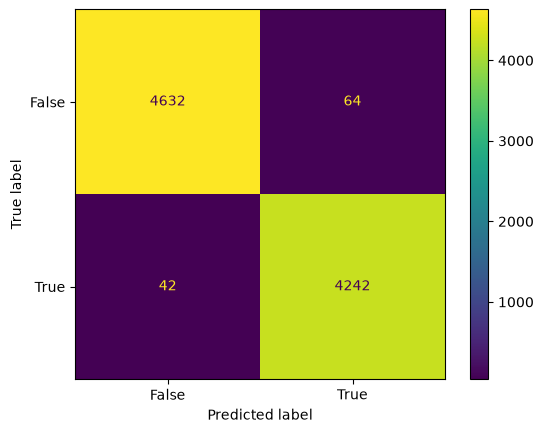

In [26]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

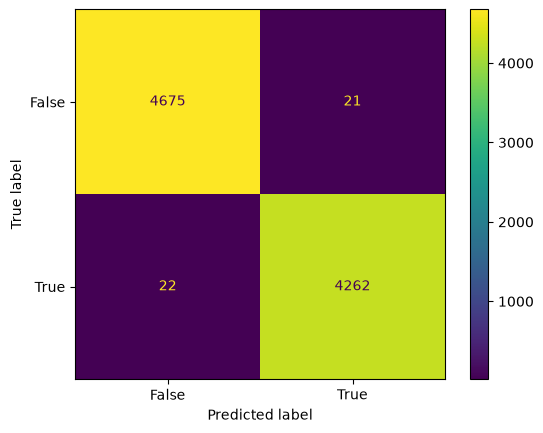

In [27]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_count)

In [28]:
print("for vectorizer: ")
print("Train_Accuracy: ", model.score(X_train_tfid, y_train))
print("Test_Accuracy: ", model.score(X_test_tfid, y_test))
print("for count_vectorizer: ")
print("Train_Accuracy: ", count_model.score(X_train_count, y_train))
print("Test_Accuracy: ", count_model.score(X_test_count, y_test))

for vectorizer: 
Train_Accuracy:  0.9921487833398296
Test_Accuracy:  0.9881959910913141
for count_vectorizer: 
Train_Accuracy:  0.9999721588061696
Test_Accuracy:  0.9952115812917595


In [29]:
for name, arg in [
    ("vectorizer", y_pred),
    ("count_vectorizer", y_pred_count)
]:
    print(f"\nfor {name}: ")
    print(f"precision score: {precision_score(y_test, arg)}")
    print(f"recall score score: {recall_score(y_test, arg)}")
    print(f"f1 score: {f1_score(y_test, arg)}")


for vectorizer: 
precision score: 0.9851370181142591
recall score score: 0.9901960784313726
f1 score: 0.9876600698486613

for count_vectorizer: 
precision score: 0.9950968946999766
recall score score: 0.9948646125116714
f1 score: 0.9949807400490254


In [30]:
errors = pd.DataFrame({
    "article": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": y_pred_count
})

errors = errors[errors["actual"] != errors["predicted"]]
print("\nMistakes:", len(errors))
print(errors[["actual", "predicted", "article"]].head(5))
print("\nShape of errors: ", errors[["actual", "predicted", "article"]].shape)


Mistakes: 43
     actual  predicted                                            article
99    False       True  BREAKING: TRUMP PICKS PENCE FOR VP…Why This Co...
364   False       True  DEMOCRAT PLAN TO INFILTRATE TRADITIONALLY RED ...
448    True      False  Trump's Washington foreign policy speech (Reut...
781    True      False  Trump draws full house at own event as he snub...
962   False       True  President Trump Travels to Orlando for Private...

Shape of errors:  (43, 3)


In [31]:
train_articles = set(X_train.str.strip().str.lower())
test_articles = X_test.str.strip().str.lower()
overlap = test_articles.isin(train_articles)

print("Test articles also in training:", overlap.sum())
print("Percent of test set:", overlap.mean() * 100)

Test articles also in training: 1830
Percent of test set: 20.378619153674833


In [32]:
df["article_key"] = df["article"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

conflicts = df.groupby("article_key")["label"].nunique()
print("Articles with conflicting labels: ", (conflicts > 1).sum())

Articles with conflicting labels:  0


In [33]:
df = df.drop_duplicates(subset="article_key").copy()
df.shape

(39100, 7)

In [34]:
df[["article_key", "article"]].head()

,article_key,article
0,donald trump sends out embarrassing new year’s...,Donald Trump Sends Out Embarrassing New Year’s...
1,drunk bragging trump staffer started russian c...,Drunk Bragging Trump Staffer Started Russian C...
2,sheriff david clarke becomes an internet joke ...,Sheriff David Clarke Becomes An Internet Joke ...
3,trump is so obsessed he even has obama’s name ...,Trump Is So Obsessed He Even Has Obama’s Name ...
4,pope francis just called out donald trump duri...,Pope Francis Just Called Out Donald Trump Duri...


In [35]:
X = df["article"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [36]:
tfid_vector = TfidfVectorizer(max_features=5000)
X_train_tfid = tfid_vector.fit_transform(X_train)
X_test_tfid = tfid_vector.transform(X_test)

count_vector = CountVectorizer(max_features=5000)
X_train_count = count_vector.fit_transform(X_train)
X_test_count = count_vector.transform(X_test)

In [37]:
tfid_model = LogisticRegression(max_iter=5000)
tfid_model.fit(X_train_tfid, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [38]:
count_model = LogisticRegression(max_iter=5000)
count_model.fit(X_train_count, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [54]:
svc_model = LinearSVC(C=1.0, max_iter=5000, random_state=42)
svc_model.fit(X_train_count, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",5000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are su

In [55]:
svc_y_pred = svc_model.predict(X_test_count)
tfid_y_pred = tfid_model.predict(X_test_tfid)
count_y_pred = count_model.predict(X_test_count)

TfidfVectorizer: 


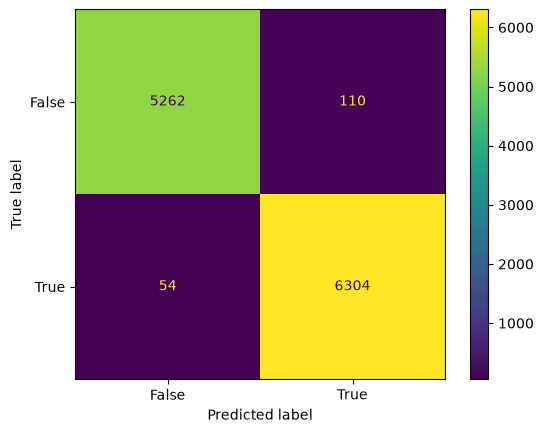

In [40]:
print("TfidfVectorizer: ")
ConfusionMatrixDisplay.from_predictions(y_test, tfid_y_pred)

CountVectorizer: 


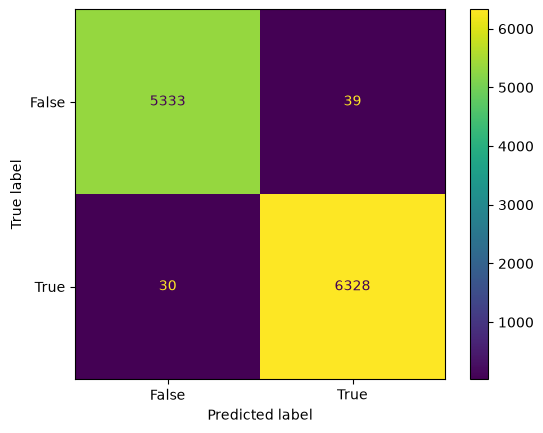

In [41]:
print("CountVectorizer: ")
ConfusionMatrixDisplay.from_predictions(y_test, count_y_pred)

In [65]:
print("Using LogisticRegression: ")
print("for vectorizer: ")
print("\nTrain_Accuracy: ", tfid_model.score(X_train_tfid, y_train))
print("Test_Accuracy: ", tfid_model.score(X_test_tfid, y_test))
print("\nfor count_vectorizer: ")
print("\nTrain_Accuracy: ", count_model.score(X_train_count, y_train))
print("Test_Accuracy: ", count_model.score(X_test_count, y_test))
print("\nUsing LinearSVC: ")
print("\nTrain_Accuracy: ", svc_model.score(X_train_count, y_train))
print("Test_Accuracy: ", svc_model.score(X_test_count, y_test))

Using LogisticRegression: 
for vectorizer: 

Train_Accuracy:  0.9900986481549141
Test_Accuracy:  0.9860187553282183

for count_vectorizer: 

Train_Accuracy:  1.0
Test_Accuracy:  0.9941176470588236

Using LinearSVC: 

Train_Accuracy:  1.0
Test_Accuracy:  0.993691389599318


In [62]:
for name, arg in [
    ("vectorizer", tfid_y_pred),
    ("count_vectorizer", count_y_pred),
    ("LinearSVC", svc_y_pred)
]:
    if(name.lower() == "linearsvc"):
        print(f"\nUsing {name} for CountVectorizer: ")
    else:   
        print(f"\nUsing LogisticRegression for {name}: ")
    print(f"\nprecision score: {precision_score(y_test, arg)}")
    print(f"recall score score: {recall_score(y_test, arg)}")
    print(f"f1 score: {f1_score(y_test, arg)}")


Using LogisticRegression for vectorizer: 

precision score: 0.9828500155908949
recall score score: 0.9915067631330607
f1 score: 0.9871594112120263

Using LogisticRegression for count_vectorizer: 

precision score: 0.9938746662478404
recall score score: 0.9952815350739226
f1 score: 0.9945776031434185

Using LinearSVC for CountVectorizer: 

precision score: 0.9930947897049592
recall score score: 0.9952815350739226
f1 score: 0.9941869599371563


In [59]:
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train_count, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.46,0.54]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[bool](2,)","[False, True]"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,5000
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [60]:
print("Baseline accuracy: ", baseline_model.score(X_test, y_test))

Baseline accuracy:  0.5420289855072464


In [68]:
df["date_parsed"] = pd.to_datetime(
    df["date"],
    format="mixed",
    errors="coerce"
)

In [69]:
print("Unparsed dates:", df["date_parsed"].isna().sum())
print(df.loc[df["date_parsed"].isna(), "date"].value_counts().head(10))

Unparsed dates: 6
date
https://100percentfedup.com/served-roy-moore-vietnamletter-veteran-sets-record-straight-honorable-decent-respectable-patriotic-commander-soldier/        1
https://100percentfedup.com/video-hillary-asked-about-trump-i-just-want-to-eat-some-pie/                                                                 1
https://100percentfedup.com/12-yr-old-black-conservative-whose-video-to-obama-went-viral-do-you-really-love-america-receives-death-threats-from-left/    1
https://fedup.wpengine.com/wp-content/uploads/2015/04/hillarystreetart.jpg                                                                               1
https://fedup.wpengine.com/wp-content/uploads/2015/04/entitled.jpg                                                                                       1
MSNBC HOST Rudely Assumes Steel Worker Would Never Let His Son Follow in His Footsteps…He Couldn’t Be More Wrong [Video]                                 1
Name: count, dtype: int64


In [70]:
pd.crosstab(df["date_parsed"].dt.year, df["label"])

label,False,True
date_parsed,,
2015.0,1644,0
2016.0,9442,4698
2017.0,6778,16497
2018.0,35,0


In [71]:
dated_df = df[df["date_parsed"].notna()].copy()

train_df = dated_df[dated_df["date_parsed"].dt.year <= 2016]
test_df = dated_df[dated_df["date_parsed"].dt.year == 2017]

print("Training labels:")
print(train_df["label"].value_counts())

print("Test labels:")
print(test_df["label"].value_counts())

Training labels:
label
False    11086
True      4698
Name: count, dtype: int64
Test labels:
label
True     16497
False     6778
Name: count, dtype: int64


In [72]:
X_train_time = train_df["article"]
y_train_time = train_df["label"]
X_test_time = test_df["article"]
y_test_time = test_df["label"]

time_count_vectorizer = CountVectorizer(max_features=5000)
X_train_time_count = time_count_vectorizer.fit_transform(X_train_time)
X_test_time_count = time_count_vectorizer.transform(X_test_time)

In [73]:
time_model = LogisticRegression(max_iter=5000)
time_model.fit(X_train_time_count, y_train_time)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [75]:
print("Train and test accuracy of time-model: ")
print(f"\nTrain accuracy: {time_model.score(X_train_time_count, y_train_time)}")
print(f"\nTest accuracy: {time_model.score(X_test_time_count, y_test_time)}")

Train and test accuracy of time-model: 

Train accuracy: 0.9999366447034972

Test accuracy: 0.9834156820622986


In [76]:
print("Precision, recall and f1 scores: ")
print(f"\nPrecision score: {precision_score(y_test_time, time_model.predict(X_test_time_count))} ")
print(f"\nRecall score: {recall_score(y_test_time, time_model.predict(X_test_time_count))} ")
print(f"\nF1 score: {f1_score(y_test_time, time_model.predict(X_test_time_count))} ")

Precision, recall and f1 scores: 

Precision score: 0.9959367111986702 

Recall score: 0.9806025337940232 

F1 score: 0.9882101405009163 


In [79]:
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {"vectorizer": time_count_vectorizer, "model":time_model},
    model_dir / "fake_news_detection.joblib"
)

['../models/fake_news_detection.joblib']

In [81]:
saved_objects = joblib.load("../models/fake_news_detection.joblib")

article_to_check = "Put the headline and article text here"
article_features = saved_objects["vectorizer"].transform([article_to_check])
prediction = saved_objects["model"].predict(article_features)[0]

print("Predicted label:", prediction)

Predicted label: False
